# Find regulons and co-regulated gene programs

A **regulon** is a transcription factor together with the genes it is predicted to regulate.
SCENIC finds regulons in RNA data in two steps. Genes whose expression follows a factor's
expression become candidate targets, and motif enrichment near those genes keeps the targets
that the factor can plausibly bind. Chromatin accessibility adds independent evidence: when
peaks that hold a factor's motif, or peaks that a CUT&RUN experiment saw the factor bind, are
more accessible in some cells than expected, the factor is likely active there.

This tutorial uses one 10x Genomics multiome sample of about 2,700 peripheral blood
mononuclear cells (PBMCs), with RNA and ATAC measured in the same cells. We will:

1. infer RNA regulons with the SCENIC workflow;
2. find gene programs, groups of genes that vary together as a unit, from RNA alone;
3. score motif accessibility in the same cells with chromVAR;
4. score the binding sites of a CUT&RUN experiment;
5. combine both modalities into enhancer-driven regulons, as SCENIC+ does.

The first cell downloads about 1.3 GB of public files: the 10x data (CC BY 4.0), a cisTarget
motif-ranking database and motif annotations from the Aerts lab, JASPAR 2024 motifs
(CC BY 4.0), the GENCODE v32 genome and gene annotation, and SPI1 CUT&RUN peaks from
ChIP-Atlas (CC BY-SA 4.0). Reading the motif-ranking database needs the `regulons` extra:
`pip install "cytearc[extra,regulons]"`.

In [1]:
# Read reference files and decompress the genome.
import gzip
import shutil
from pathlib import Path
from urllib.request import Request, urlopen

# Plot activity tables and embeddings.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run CyteArc analyses and regulon methods.
import cytearc
from cytearc import regulons as rg

# Keep routine logs and progress bars out of the results, and show whole gene lists.
cytearc.configure_output(level="WARNING", progress=False)
pd.set_option("display.max_colwidth", 120)

# Keep downloaded reference files in one folder.
inputs = Path("regulon_inputs")
inputs.mkdir(exist_ok=True)


# Download each file once; some hosts refuse Python's default client name.
def fetch(url):
    path = inputs / url.rsplit("/", 1)[1]
    if not path.exists():
        request = Request(url, headers={"User-Agent": "CyteArc documentation"})
        partial = path.with_name(path.name + ".part")
        with urlopen(request) as response, open(partial, "wb") as target:
            shutil.copyfileobj(response, target)
        partial.rename(path)
    return path


# The 10x Genomics PBMC multiome sample (Cell Ranger ARC 2.0, GRCh38).
matrix_h5 = fetch(
    "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_3k/"
    "pbmc_granulocyte_sorted_3k_filtered_feature_bc_matrix.h5"
)

# Human transcription factors, a motif-ranking database, and motif annotations.
tf_list = fetch("https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt")
ranking_db = fetch(
    "https://resources.aertslab.org/cistarget/databases/homo_sapiens/hg38/refseq_r80/"
    "mc_v10_clust/gene_based/hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather"
)
motif_table = fetch("https://resources.aertslab.org/cistarget/motif2tf/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl")

# JASPAR motifs, and the genome and genes that the 10x peaks were called against.
jaspar = fetch(
    "https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt"
)
gencode = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/"
genome_gz = fetch(gencode + "GRCh38.primary_assembly.genome.fa.gz")
gene_gtf = fetch(gencode + "gencode.v32.primary_assembly.annotation.gtf.gz")

# SPI1 (PU.1) CUT&RUN peaks from primary human monocytes (GEO GSM8669389).
spi1_cutrun = fetch("https://chip-atlas.dbcls.jp/data/hg38/eachData/bed05/SRX26995709.05.bed")

# Motif scanning reads the genome at many positions, so decompress it once.
genome_fa = inputs / "GRCh38.primary_assembly.genome.fa"
if not genome_fa.exists():
    with gzip.open(genome_gz, "rb") as source, open(genome_fa, "wb") as target:
        shutil.copyfileobj(source, target)

Started: 2026-10-13T02:01:49.879064Z | Wall time: 607.745 s

## Build the store and name the populations

Convert the 10x matrix into a CyteArc store. Its RNA and ATAC peak counts become two assays
over the same cells. The standard RNA pipeline then selects cells and genes, builds the
neighbor graph and UMAP, and clusters the cells.

In [2]:
# Write both assays of the 10x matrix into one store.
cytearc.CrToZarr(cytearc.CrH5Reader(str(matrix_h5)), zarr_loc="pbmc_multiome.zarr").dump()

# Open the store so that analyses can save their results.
ds = cytearc.DataStore("pbmc_multiome.zarr", default_assay="RNA", min_features_per_cell=-1, nthreads=4)

# Run the standard RNA recipe: cell and gene selection, graph, UMAP, and clusters.
run = ds.pipeline.run(label="baseline")

# Keep the cells that the pipeline analysed.
cells = run["analysis_cell_selection"]
analysed = np.asarray(run.cells.fetch_all("I"), dtype=bool)
ds

DataStore has 2711 (2711) cells with 2 assays: ATAC RNA
   Cell metadata:
            'I', 'ids', 'names', 'ATAC_nCounts', 'ATAC_nFeatures', 
            'RNA_nCounts', 'RNA_nFeatures', 'RNA_percentMito', 'RNA_percentRibo'
   ATAC assay has 98319 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'interval', 'nCells'
   RNA assay has 36601 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'interval', 'nCells'

Started: 2026-10-13T02:11:57.629637Z | Wall time: 94.402 s

Name the clusters with a small panel of canonical markers. Each cluster takes the panel whose
mean expression, scaled across clusters, is highest. These names make the results easier to
read; they are not a substitute for the annotation workflow in [](annotation.ipynb).

In [3]:
# Canonical PBMC marker panels.
panels = {
    "CD14 monocyte": ["CD14", "LYZ", "VCAN", "S100A8"],
    "CD16 monocyte": ["FCGR3A", "MS4A7", "LST1"],
    "Dendritic cell": ["FCER1A", "CD1C", "CLEC10A"],
    "Plasmacytoid DC": ["LILRA4", "IL3RA", "CLEC4C"],
    "B cell": ["MS4A1", "CD79A", "BANK1", "PAX5"],
    "CD4 T cell": ["CD3E", "IL7R", "CD4"],
    "CD8 T cell": ["CD3E", "CD8A", "CD8B"],
    "NK cell": ["NKG7", "GNLY", "KLRD1"],
}

# Average the normalized expression of every gene within each cluster.
means = ds.compare.compute_bulk(run["clusters"], feature_label="name")
means = means.loc[~means.index.duplicated(keep=False)]

# Scale each gene across clusters, then score every panel in every cluster.
scaled = means.sub(means.mean(axis=1), axis=0).div(means.std(axis=1).replace(0, 1), axis=0)
panel_scores = pd.DataFrame({name: scaled.loc[genes].mean() for name, genes in panels.items()})

# Name each analysed cell after its cluster's best panel.
cluster_names = panel_scores.idxmax(axis=1)
cell_type = cluster_names.reindex(run.cells.fetch("clusters").astype(str)).to_numpy()
pd.Series(cell_type).value_counts()

CD4 T cell         858
CD14 monocyte      719
CD8 T cell         525
B cell             192
CD16 monocyte      121
NK cell            102
Dendritic cell      66
Plasmacytoid DC     29
Name: count, dtype: int64

Started: 2026-10-13T02:13:32.034409Z | Wall time: 0.620 s

## Infer RNA regulons

GRNBoost2 asks, for every gene, how well each transcription factor's expression predicts it,
using gradient-boosted trees on raw counts. `ds.regulons.grn` runs it with the pySCENIC
settings and saves the network as an artifact. It is the slowest step, so this page fits it
on 500 sampled cells, the highly variable genes, and every transcription factor detected in
at least 1% of cells. Use all cells and expressed genes in a real analysis.

In [4]:
# Sample 500 analysed cells for network inference.
rng = np.random.default_rng(0)
sample = np.zeros(ds.cells.N, dtype=bool)
sample[rng.choice(np.flatnonzero(analysed), size=500, replace=False)] = True
ds.cells.insert("grn_cells", sample, overwrite=True)
grn_cells = ds.snapshot_cell_selection("grn_cells")

# Read the human transcription factors that the motif annotations cover.
tfs = [line.strip() for line in open(tf_list) if line.strip()]

# Model the highly variable genes and the factors detected in 1% of analysed cells.
names = np.asarray(ds.RNA.feats.fetch_all("names")).astype(str)
variable = np.asarray(run.features.fetch_all("highly_variable_features"), dtype=bool)
detected = ds.features.detected(cells, min_cells=int(analysed.sum() // 100))
expressed = np.asarray(ds.artifacts.load(detected)["values"][:], dtype=bool)
grn_genes = ds.features.snapshot(from_assay="RNA", mask=variable | (expressed & np.isin(names, tfs)))

# Score every factor-to-gene link with GRNBoost2.
grn = ds.regulons.grn(grn_cells, features=grn_genes, tfs=tfs, random_seed=777)
adjacencies = ds.regulons.load_grn(grn).adjacencies
adjacencies.head()

,TF,target,importance,correlation
0,IRF7,CLEC4C,76.803128,0.864336
1,IRF7,LINC01478,76.534487,0.736089
2,IRF7,PTPRS,71.807399,0.713395
3,IRF7,RHEX,71.732840,0.746469
4,IRF7,TCF4,68.916118,0.801061


Started: 2026-10-13T02:13:32.656378Z | Wall time: 181.366 s

Each row is a link from a factor to a target gene. `importance` measures how much the factor
helps predict the gene, and `correlation` gives the direction. pySCENIC turns each factor's
strongest activating links into several candidate modules, then keeps only the targets that a
motif annotated to that factor ranks highly. The database ranks every gene by the best match
of each motif from 10 kb upstream of its transcription start site to 10 kb past its end.

In [5]:
# Build pySCENIC's candidate modules from the activating links.
modules = rg.modules_from_adjacencies(adjacencies)

# Keep module targets that an enriched motif of the module's factor recovers.
database = rg.RankingDatabase(ranking_db)
annotations = rg.read_motif_annotations(motif_table)
enriched = rg.prune_modules(modules, [database], annotations, nthreads=4)

# Merge every factor's surviving targets into one regulon.
regulons = rg.regulons_from_motifs(enriched)
regulons.groupby("regulon").size().sort_values(ascending=False).head(10)

regulon
KLF4(+)     212
BACH1(+)    209
KLF6(+)     198
SPI1(+)     177
FOXN2(+)    120
CHD1(+)     118
KLF12(+)    110
BCL6(+)     104
NR3C1(+)    103
IKZF1(+)    101
dtype: int64

Started: 2026-10-13T02:16:34.024829Z | Wall time: 16.357 s

Score every regulon in every analysed cell with AUCell. A cell scores high when the regulon's
genes are among its most strongly expressed genes. The regulon specificity score (RSS) then
measures how concentrated each regulon's activity is in each population; 1 means the regulon
is active only, and evenly, in that population.

In [6]:
# Score regulons with at least ten genes in every analysed cell.
regulon_net = regulons.rename(columns={"regulon": "source"})
regulon_auc = ds.scores.load(ds.scores.aucell(regulon_net, cells, features=run["feature_universe"], tmin=10))
activity = pd.DataFrame(np.asarray(regulon_auc.data.compute()), columns=regulon_auc.source_names)

# List the three most specific regulons of each population.
rss = rg.regulon_specificity(activity, cell_type)
rss.apply(lambda scores: ", ".join(scores.nlargest(3).index), axis=1).to_frame("most specific regulons")

,most specific regulons
group,
NK cell,"TBX21(+), EOMES(+), IKZF2(+)"
CD14 monocyte,"ATF3(+), STAT2(+), CEBPD(+)"
B cell,"EBF1(+), PATZ1(+), TCF4(+)"
CD8 T cell,"EOMES(+), TBX21(+), ETS1(+)"
CD4 T cell,"ETS1(+), NFATC2(+), BACH2(+)"
CD16 monocyte,"BATF3(+), CEBPB(+), CEBPA(+)"
Plasmacytoid DC,"RUNX2(+), GABPB1(+), ELK1(+)"
Dendritic cell,"RUNX2(+), CEBPD(+), ZNF467(+)"


Started: 2026-10-13T02:16:50.384585Z | Wall time: 13.529 s

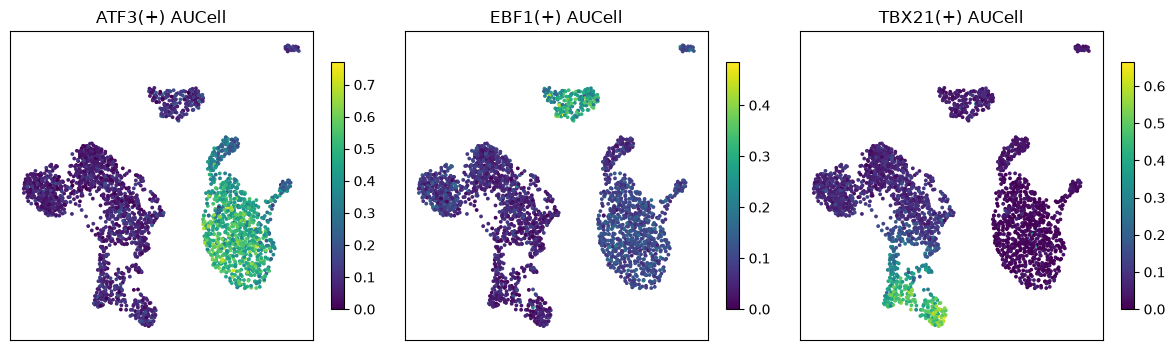

Started: 2026-10-13T02:17:03.915765Z | Wall time: 0.318 s

In [7]:
# Read the UMAP coordinates of the analysed cells.
umap = run.cells.to_pandas_dataframe(["umap_1", "umap_2"])

# Pick the most specific regulon of three lineages.
lineages = [name for name in ("CD14 monocyte", "B cell", "NK cell") if name in rss.index]
shown = list(dict.fromkeys(rss.loc[name].idxmax() for name in lineages))

# Show each regulon's activity on the UMAP.
figure, axes = plt.subplots(1, len(shown), figsize=(4 * len(shown), 3.6), squeeze=False)
for axis, name in zip(axes[0], shown):
    points = axis.scatter(umap["umap_1"], umap["umap_2"], c=activity[name], s=3, cmap="viridis")
    axis.set_title(f"{name} AUCell")
    axis.set_xticks([])
    axis.set_yticks([])
    figure.colorbar(points, ax=axis, shrink=0.8)
figure.tight_layout()
plt.show()

The most specific regulons are known lineage factors: TBX21 and EOMES in NK cells, EBF1 in
B cells, CEBPA and CEBPB in CD16 monocytes, and ETS1 and BACH2 in CD4 T cells.

Regulons that are active in the same cells may act together. The connection specificity
index (CSI) of two regulons is the fraction of all regulons that correlate less with both of
them than they do with each other. Clustering the CSI groups the regulons into modules, as
SCENIC analyses do.

In [8]:
# Compare regulon activities across cells and group them into five modules.
csi = rg.connection_specificity(activity)
regulon_groups = rg.regulon_modules(csi, n_modules=5)

# List the regulons of each module and the population where the module is most active.
module_activity = activity.T.groupby(regulon_groups).mean().T.groupby(cell_type).mean()
pd.DataFrame({
    "regulons": regulon_groups.groupby(regulon_groups).apply(lambda group: ", ".join(group.index[:8])),
    "most active in": module_activity.idxmax(),
})

,regulons,most active in
module,,
1,"ATF3(+), BACH1(+), BATF3(+), BCL6(+), CEBPA(+)...",CD14 monocyte
2,"ARID3A(+), ATF5(+), CHURC1(+), CLOCK(+), CTBP1...",Plasmacytoid DC
3,"BACH2(+), BHLHE40(+), BPTF(+), EOMES(+), ETS1(...",CD8 T cell
4,"CTCF(+), EGR3(+), ELF4(+), FOXJ2(+), GMEB2(+),...",CD14 monocyte
5,"BCLAF1(+), ELF1(+), ELK3(+), ETV7(+), NFE2L2(+...",NK cell


Started: 2026-10-13T02:17:04.237365Z | Wall time: 0.076 s

## Find co-regulated gene programs

A regulon starts from a known factor. A gene program starts from the genes: genes that rise
and fall together across many groups of similar cells are likely regulated as a unit, whether
or not we know the factor. This needs only RNA, so it applies to any scRNA-seq dataset.

Pool the analysed cells into about a hundred small groups (metacells) to average out
sampling noise. Then connect each variable gene to the genes it correlates with most across
metacells and split that graph into programs with Leiden.

In [9]:
# Group the analysed cells into small, similar groups with a fine Leiden partition.
fine = ds.clusters.leiden(run["connectivity_map"], resolution=15)
metacell = np.full(ds.cells.N, -1)
metacell[analysed] = np.asarray(ds.artifacts.load(fine)["values"][:])
ds.cells.insert("metacell", metacell, overwrite=True)

# Sum RNA and ATAC counts within each metacell and convert them to log counts per million.
profiles = {}
for assay, label in (("RNA", "name"), ("ATAC", "id")):
    sums = ds.compare.compute_bulk(
        "metacell", from_assay=assay, cell_selection=cells, aggr_type="sum",
        feature_label=label, remove_empty_features=False, null_vals=[-1],
    )
    sums = sums.loc[~sums.index.duplicated(keep=False)].T.astype(float)
    profiles[assay] = np.log1p(sums.div(sums.sum(axis=1), axis=0) * 1e6)

# Split the variable genes into programs of co-varying genes.
program_genes = [gene for gene in names[variable] if gene in profiles["RNA"].columns]
programs = rg.gene_programs(profiles["RNA"][program_genes].to_numpy(), program_genes)
programs.groupby("program", sort=False)["gene"].agg(
    size="size", leading_genes=lambda genes: ", ".join(genes.head(8))
)

,size,leading_genes
program,,
P1,239,"ABLIM1, BCL11B, CAMK4, LEF1, TC2N, RASGRF2, ZE..."
P2,216,"RIN2, GLT1D1, CLEC7A, PLXDC2, SLC24A4, WDFY3, ..."
P3,133,"LINC02397, CD19, KLHL14, FCRL2, PAX5, FCRLA, I..."
P4,108,"PTGDR, PPP2R2B, CST7, XCL2, PDGFD, LGR6, S1PR5..."
P5,87,"MEF2C, SYK, KYNU, TBC1D9, WDFY4, ARHGAP24, CD7..."
P6,26,"LINC01478, LRRC26, P3H2, PHEX, TNFRSF21, CLEC4..."


Started: 2026-10-13T02:17:04.315384Z | Wall time: 40.275 s

Each program lists its genes by `membership`, the correlation of a gene with the program's
average profile, so the leading genes are the most typical. They already suggest identities:
T-cell genes in P1 (BCL11B, LEF1, IL7R), monocyte genes in P2 (CLEC7A, KLF4), B-cell genes in
P3 (CD19, PAX5), cytotoxic genes in P4 (CST7, XCL2), antigen-presentation genes in P5 (CD74,
IRF8), and plasmacytoid DC genes in P6 (CLEC4C, LRRC26). Score each program in every
cell with AUCell, as for the regulons.

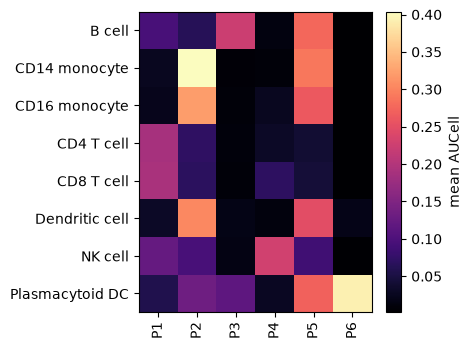

Started: 2026-10-13T02:17:44.592548Z | Wall time: 1.116 s

In [10]:
# Score each program in every analysed cell.
program_net = programs.rename(columns={"program": "source", "gene": "target"})
program_auc = ds.scores.load(ds.scores.aucell(program_net, cells, features=run["feature_universe"], tmin=10))
program_activity = pd.DataFrame(np.asarray(program_auc.data.compute()), columns=program_auc.source_names)

# Show the mean activity of each program in each population.
program_means = program_activity.groupby(cell_type).mean()
figure, axis = plt.subplots(figsize=(0.45 * program_means.shape[1] + 2, 3.6))
image = axis.imshow(program_means.to_numpy(), cmap="magma", aspect="auto")
axis.set_xticks(range(program_means.shape[1]), program_means.columns, rotation=90)
axis.set_yticks(range(program_means.shape[0]), program_means.index)
figure.colorbar(image, ax=axis, label="mean AUCell")
figure.tight_layout()
plt.show()

Each program is most active where its genes suggest: P2 in monocytes and dendritic cells, P3
in B cells, P4 in NK cells, and P6 in plasmacytoid DCs, while P1 marks T cells and P5 the
antigen-presenting B cells, monocytes, and dendritic cells.

Which factors might drive a program? The programs were found without any factor, so compare
them with the regulons: a program that shares many genes with a regulon is a candidate unit
of that factor. The test counts shared genes among the variable genes that both could
contain.

In [11]:
# Test every program for overlap with every regulon.
overlaps = rg.set_overlaps(
    programs.rename(columns={"program": "set"}),
    regulons.rename(columns={"regulon": "set", "target": "gene"}),
    program_genes,
)

# List the three most significant regulons of each program.
shared = overlaps[overlaps["q_value"] < 0.05].sort_values("p_value").groupby("query").head(3)
shared.groupby("query")["reference"].agg(", ".join).to_frame("overlapping regulons")

,overlapping regulons
query,
P1,"ETS1(+), KLF12(+), MAF(+)"
P2,"KLF4(+), KLF6(+), BACH1(+)"
P3,"TCF4(+), EBF1(+)"
P4,"TBX21(+), IKZF2(+), EOMES(+)"
P5,"TCF4(+), BACH1(+), KLF4(+)"
P6,"TCF3(+), ARID3A(+)"


Started: 2026-10-13T02:17:45.711182Z | Wall time: 0.072 s

The overlaps tie programs to lineage factors: the T-cell program to ETS1, the monocyte
program to KLF4, the B-cell program to EBF1, and the NK program to TBX21 and EOMES.

A second route needs no regulons: test each program's own genes for motif enrichment with the
database that pruned the regulons. Large programs enrich many weak motifs, so keep the factors
whose own expression follows the program across metacells. Both routes nominate candidates
to test, not demonstrated regulators.

In [12]:
# Find motifs that rank each program's genes highly and name their factors.
program_tfs = rg.program_regulators(programs, database, annotations).drop_duplicates(["program", "TF"])

# Score each program in every metacell.
program_profiles = rg.program_scores(profiles["RNA"][program_genes].to_numpy(), program_genes, programs)

# Correlate each varying factor's expression with its program across metacells.
expression = profiles["RNA"].loc[:, profiles["RNA"].std() > 0]
program_tfs = program_tfs[program_tfs["TF"].isin(expression.columns)].copy()
program_tfs["correlation"] = [
    np.corrcoef(expression[tf], program_profiles[program])[0, 1]
    for program, tf in zip(program_tfs["program"], program_tfs["TF"])
]

# Keep the three best-correlated factors of each program.
supported = program_tfs[program_tfs["correlation"] > 0.6].sort_values("correlation", ascending=False)
supported.groupby("program").head(3).sort_values("program", kind="stable")[["program", "TF", "motif", "NES", "correlation"]]

,program,TF,motif,NES,correlation
135,P1,ETS1,tfdimers__MD00364,3.145663,0.915059
340,P1,BACH2,tfdimers__MD00569,3.016201,0.904464
199,P1,IKZF3,metacluster_133.2,3.093878,0.851704
447,P2,RXRA,tfdimers__MD00081,3.066833,0.857690
453,P2,VDR,tfdimers__MD00081,3.066833,0.781318
437,P2,ETS2,tfdimers__MD00081,3.066833,0.764151
1152,P5,TCF4,tfdimers__MD00164,3.038974,0.887450
816,P5,PLAGL1,metacluster_133.2,3.250456,0.822998
1002,P5,SPI1,metacluster_24.2,3.220364,0.795150


Started: 2026-10-13T02:17:45.784870Z | Wall time: 1.861 s

Only three of the six programs have an enriched motif whose factor follows them closely, and
the factors agree with the overlaps for the T-cell program (ETS1) and the antigen-presentation
program (TCF4). A shared regulon is stronger evidence than motif enrichment of a large program.

## Score motif accessibility in the same cells

chromVAR asks whether a cell has more ATAC fragments in the peaks that hold a motif than its
sequencing depth and those peaks' average accessibility predict. It compares each motif's peaks
with background peaks of similar GC content and accessibility. First find the peaks that
contain each motif. To keep this page short, scan the JASPAR motifs of a panel of immune
factors; scan the whole collection for discovery.

In [13]:
# Use every peak with a fragment among the analysed cells.
peaks = ds.features.detected(cells, from_assay="ATAC", min_cells=1)
peak_index = np.flatnonzero(ds.artifacts.load(peaks)["values"][:])
peak_ids = np.asarray(ds.ATAC.feats.fetch_all("ids")).astype(str)[peak_index]
chroms, starts, ends = rg.parse_coordinate_ids(peak_ids)

# Keep the first JASPAR motif of each factor that marks PBMC populations.
panel = ["SPI1", "CEBPA", "CEBPB", "IRF8", "KLF4", "PAX5", "EBF1", "POU2F2", "TBX21",
         "EOMES", "RUNX3", "GATA3", "TCF7", "LEF1", "CTCF", "IRF4", "MEF2C", "NFKB1"]
first_motif = {}
for motif in rg.read_jaspar_motifs(jaspar):
    first_motif.setdefault(motif.name.upper(), motif)
motifs = [first_motif[name] for name in panel if name in first_motif]

# Find the peaks that hold a match of each motif on either strand.
with rg.IndexedFasta(genome_fa) as genome:
    matches = rg.match_motifs(chroms, starts, ends, genome, motifs, names=peak_ids)
matches["motif_name"].str.upper().value_counts().to_frame("peaks with a match").T

motif_name,SPI1,KLF4,CTCF,MEF2C,EBF1,RUNX3,IRF8,CEBPA,POU2F2,EOMES,NFKB1,IRF4,TCF7,GATA3,TBX21,LEF1,CEBPB,PAX5
peaks with a match,43059,31982,28485,26353,17695,13727,12797,12461,12387,11427,11343,11160,10664,9868,8928,8819,3293,3108


Started: 2026-10-13T02:17:47.649455Z | Wall time: 34.104 s

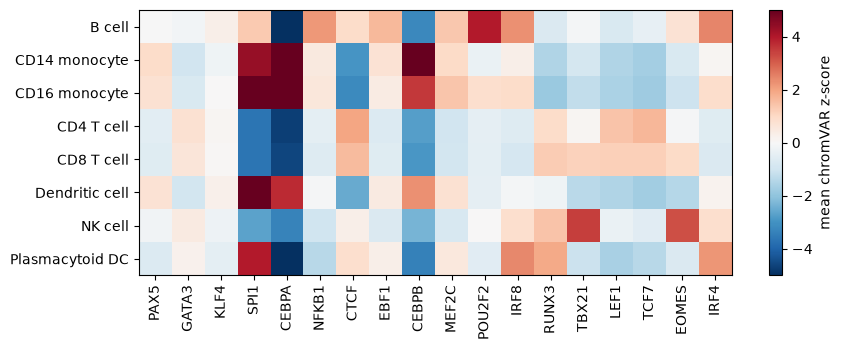

Started: 2026-10-13T02:18:21.756344Z | Wall time: 40.900 s

In [14]:
# Score motif accessibility deviations in every analysed cell.
motif_scores = ds.scores.load(
    ds.scores.chromvar(matches, cells, from_assay="ATAC", features=peaks, genome=str(genome_fa))
)
motif_names = {motif.motifId: motif.name.upper() for motif in motifs}
motif_z = pd.DataFrame(np.asarray(motif_scores.data.compute()), columns=[motif_names[s] for s in motif_scores.source_names])

# Average the z-scores within each population.
motif_means = motif_z.groupby(cell_type).mean()
figure, axis = plt.subplots(figsize=(9, 3.6))
image = axis.imshow(motif_means.to_numpy(), cmap="RdBu_r", vmin=-5, vmax=5, aspect="auto")
axis.set_xticks(range(motif_means.shape[1]), motif_means.columns, rotation=90)
axis.set_yticks(range(motif_means.shape[0]), motif_means.index)
figure.colorbar(image, ax=axis, label="mean chromVAR z-score")
figure.tight_layout()
plt.show()

Motif accessibility agrees with the RNA regulons. The CEBPA and CEBPB motifs are most
accessible in monocytes; SPI1 (PU.1) in monocytes and dendritic cells; POU2F2 in B cells;
IRF4 and IRF8 in B cells and plasmacytoid DCs; TBX21 and EOMES in NK cells; and TCF7 and LEF1
in T cells.
Related factors share motifs, so each column measures a motif family rather than one factor.
The PAX5 motif does not separate B cells here and the EBF1 motif does so only weakly, so a
missing deviation is not evidence that a factor is inactive.

## Score CUT&RUN binding sites

A CUT&RUN experiment for one factor maps where that factor was bound, without relying on a
motif. Map the SPI1 (PU.1) peaks from primary monocytes onto the ATAC peaks and score them in
the same way. Any set of regions works: CUT&Tag or ChIP-seq peaks, or peaks of another
dataset.

In [15]:
# Map the SPI1 CUT&RUN peaks onto the ATAC peaks.
binding = rg.binding_cistromes({"SPI1": spi1_cutrun}, peak_ids)
print(f"{len(binding):,} ATAC peaks overlap an SPI1 CUT&RUN peak")

# Score the accessibility of the bound peaks in every analysed cell.
bound_scores = ds.scores.load(
    ds.scores.chromvar(binding, cells, from_assay="ATAC", features=peaks, genome=str(genome_fa))
)
bound_z = pd.Series(np.asarray(bound_scores.data.compute())[:, 0])

# Compare the mean z-scores of the bound peaks and of the SPI1 motif in each population.
pd.DataFrame({
    "SPI1 CUT&RUN peaks": bound_z.groupby(cell_type).mean(),
    "SPI1 motif": motif_means["SPI1"],
}).round(2)

2,519 ATAC peaks overlap an SPI1 CUT&RUN peak


,SPI1 CUT&RUN peaks,SPI1 motif
B cell,-1.34,1.33
CD14 monocyte,10.69,4.35
CD16 monocyte,10.75,5.69
CD4 T cell,-6.87,-3.65
CD8 T cell,-6.83,-3.67
Dendritic cell,11.32,7.17
NK cell,-4.64,-2.67
Plasmacytoid DC,0.32,3.96


Started: 2026-10-13T02:19:02.658693Z | Wall time: 38.724 s

The sites that SPI1 occupies in monocytes separate myeloid cells from lymphocytes more sharply
than its motif does, because the motif also counts sites that the factor does not use. B cells
and plasmacytoid DCs, where the motif is moderately accessible, show no enrichment of these
monocyte sites: binding sites differ between cell types even for one factor.

## Build enhancer-driven regulons

With RNA and ATAC from the same cells, we can ask which peaks near a gene track its
expression. SCENIC+ links each peak within 150 kb of a gene body to that gene by a
gradient-boosting importance and a rank correlation across metacells. A factor's
**eRegulon** keeps its links whose peaks hold its motif (or its binding sites) and whose
genes rank high in the factor's GRNBoost2 network, tested by preranked GSEA.

In [16]:
# Find candidate peaks within 150 kb of each modelled gene.
genes_table = rg.read_gene_annotation(gene_gtf, gene_types={"protein_coding"}).drop_duplicates("gene_name")
search = rg.link_regions_to_genes(chroms, starts, ends, genes_table, upstream=150_000,
                                  downstream=150_000, anchor="gene_body")
candidates = pd.DataFrame({"region": peak_ids[search["region"]], "gene": search["gene_name"]})
candidates = candidates[candidates["gene"].isin(set(adjacencies["target"]) & set(profiles["RNA"].columns))]

# Score every candidate link across metacells.
links = rg.region_gene_links(
    profiles["ATAC"].to_numpy(), profiles["ATAC"].columns, profiles["RNA"].to_numpy(),
    profiles["RNA"].columns, candidates, nthreads=4,
)

# Assign motif-matched peaks to their factors.
motif_factors = pd.DataFrame(
    [(motif.motifId, motif.name.upper(), "direct") for motif in motifs], columns=["motif", "TF", "category"]
)
cistromes = rg.cistromes_from_motifs(matches, motif_factors)

# Build eRegulons from the motif cistromes and from the SPI1 CUT&RUN peaks.
eregulons = pd.concat([
    rg.build_eregulons(cistromes, links, adjacencies, nthreads=4),
    rg.build_eregulons(binding, links, adjacencies, label="CUTRUN", nthreads=4),
])
sizes = eregulons.groupby("eRegulon").agg(peaks=("region", "nunique"), genes=("gene", "nunique"))
sizes[sizes.index.str.endswith("+/+")]

,peaks,genes
eRegulon,,
CEBPA_direct_+/+,141,64
CEBPB_direct_+/+,36,32
CTCF_direct_+/+,221,83
EBF1_direct_+/+,182,67
EOMES_direct_+/+,44,22
GATA3_direct_+/+,68,35
IRF4_direct_+/+,91,45
IRF8_direct_+/+,200,91
KLF4_direct_+/+,607,154


Started: 2026-10-13T02:19:41.385816Z | Wall time: 741.454 s

An eRegulon name gives its factor, the evidence for binding (`direct` motif annotation or
`CUTRUN` peaks), and two signs: whether the factor's expression rises (`+`) or falls (`-`)
with its target genes, and whether the linked peaks open (`+`) or close (`-`) with them. The
table lists the `+/+` eRegulons, activators whose target peaks open with the targets; the
other sign classes are kept in `eregulons`. Score the target genes of each eRegulon as before.

In [17]:
# Score the target genes of every eRegulon in every analysed cell.
eregulon_net = eregulons[["eRegulon", "gene"]].drop_duplicates().set_axis(["source", "target"], axis=1)
eregulon_auc = ds.scores.load(ds.scores.aucell(eregulon_net, cells, features=run["feature_universe"], tmin=10))
eregulon_activity = pd.DataFrame(np.asarray(eregulon_auc.data.compute()), columns=eregulon_auc.source_names)

# Find the population where each activator eRegulon is most active.
eregulon_means = eregulon_activity.loc[:, eregulon_activity.columns.str.endswith("+/+")].groupby(cell_type).mean()
pd.DataFrame({"most active in": eregulon_means.idxmax(), "mean AUCell": eregulon_means.max().round(3)})

,most active in,mean AUCell
CEBPA_direct_+/+,CD16 monocyte,0.523
CEBPB_direct_+/+,CD16 monocyte,0.660
CTCF_direct_+/+,NK cell,0.205
EBF1_direct_+/+,B cell,0.457
EOMES_direct_+/+,NK cell,0.452
GATA3_direct_+/+,NK cell,0.293
IRF4_direct_+/+,Plasmacytoid DC,0.630
IRF8_direct_+/+,Plasmacytoid DC,0.522
KLF4_direct_+/+,CD14 monocyte,0.584
LEF1_direct_+/+,CD4 T cell,0.444


Started: 2026-10-13T02:32:02.844057Z | Wall time: 0.763 s

The activator eRegulons of lineage factors are most active where expected: the CEBP, SPI1,
and KLF4 eRegulons in monocytes, EBF1 and PAX5 in B cells, EOMES, TBX21, and RUNX3 in NK cells,
IRF4 and IRF8 in plasmacytoid DCs, and LEF1 and TCF7 in CD4 T cells. The SPI1 eRegulon built
from CUT&RUN peaks agrees with the one built from motifs.

## What to report

- Regulons, programs, and eRegulons are hypotheses. GRNBoost2 is stochastic: rerun
  `ds.regulons.grn` with another `random_seed` and report the regulons that persist.
- Use reference files that match the data: the genome build and gene annotation of the peaks,
  and a cisTarget database for the same species and gene names.
- A motif is shared by related factors, so a motif score names a family; pair it with the
  factor's expression or binding data before naming the factor.
- Binding data describe the cells that were profiled; the SPI1 peaks here come from
  monocytes.

[The methods page](../reference/methods.md) summarizes how these methods were validated
against pySCENIC 0.12.1 and chromVAR, and the [regulons API reference](/api/regulons.html)
lists every function.